# 02 — BERT: andamento e risultati

BERT viene addestrato sul server `artes4` (script `02_bert.py`), sulla versione **min0** con i **fold per gruppo**:
gli stessi dati e gli stessi fold del classificatore a feature (notebook 01).
Questo notebook copia dal server il log e i fold già finiti, mostra a che punto è l'addestramento e
confronta BERT con il classificatore a feature **sugli stessi fold**, livello per livello.

**Prima di eseguirlo** apri dal terminale la connessione al server (chiede la password una volta, poi resta aperta in background):

```bash
ssh -M -S ~/.ssh/artes4.sock -fN fabio.pinelli@10.181.100.6
```

Il notebook si può rieseguire quante volte si vuole: ogni volta riprende i fold nuovi.

In [1]:
import re
import subprocess
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from comune import RESULTS, LIVELLI, per_testata, tabella_per_fold

SERVER = "fabio.pinelli@10.181.100.6"
SOCKET = str(Path.home() / ".ssh" / "artes4.sock")
REMOTO = "~/John/WebScience2027/Results/2-classificazione/"
LOCALE = Path(RESULTS)
VERSIONE, SCHEMA = "min0", "fold_gruppo"
EPOCHE, FOLD = 5, 5

## 1. Copia dal server

In [2]:
(LOCALE / "bert").mkdir(exist_ok=True)
for sorgente, destinazione in [(REMOTO + "avanzamento_bert.log", LOCALE), (REMOTO + "bert/*.csv", LOCALE / "bert")]:
    esito = subprocess.run(["scp", "-o", f"ControlPath={SOCKET}", "-o", "BatchMode=yes", f"{SERVER}:{sorgente}", str(destinazione)],
                           capture_output=True, text=True)
    if esito.returncode == 0:
        print(f"copiato: {sorgente}")
    elif "No such file" in esito.stderr:
        print(f"ancora niente sul server: {sorgente}")
    else:
        print(f"ERRORE (la connessione è aperta? vedi in alto): {esito.stderr.strip()}")

copiato: ~/John/WebScience2027/Results/2-classificazione/avanzamento_bert.log


copiato: ~/John/WebScience2027/Results/2-classificazione/bert/*.csv


## 2. A che punto è

In [3]:
log = [r for r in (LOCALE / "avanzamento_bert.log").read_text().splitlines() if f"{VERSIONE} {SCHEMA}" in r]
print("\n".join(log[-10:]))

epoche = pd.DataFrame([
    {"fold": int(m[1]), "epoca": int(m[2]), "secondi": int(m[3]), "loss": float(m[4])}
    for m in (re.search(r"fold (\d+): epoca (\d+)/\d+ finita in (\d+) s, loss media ([\d.]+)", r) for r in log) if m])

fatte = len(epoche)
print(f"\nepoche finite: {fatte} su {EPOCHE * FOLD}")
if fatte:
    restanti = (EPOCHE * FOLD - fatte) * epoche.secondi.mean()
    print(f"durata media di un'epoca: {epoche.secondi.mean() / 60:.0f} min -> tempo stimato che manca: {restanti / 3600:.1f} ore")

2026-10-13 15:34:09  min0 fold_gruppo fold 5: epoca 4/5, passo 300/437, loss 0.2642
2026-10-13 15:34:51  min0 fold_gruppo fold 5: epoca 4/5, passo 400/437, loss 0.2704
2026-10-13 15:35:06  min0 fold_gruppo fold 5: epoca 4/5 finita in 183 s, loss media 0.2693
2026-10-13 15:35:48  min0 fold_gruppo fold 5: epoca 5/5, passo 100/437, loss 0.1407
2026-10-13 15:36:30  min0 fold_gruppo fold 5: epoca 5/5, passo 200/437, loss 0.1450
2026-10-13 15:37:12  min0 fold_gruppo fold 5: epoca 5/5, passo 300/437, loss 0.1453
2026-10-13 15:37:53  min0 fold_gruppo fold 5: epoca 5/5, passo 400/437, loss 0.1475
2026-10-13 15:38:09  min0 fold_gruppo fold 5: epoca 5/5 finita in 183 s, loss media 0.1487
2026-10-13 15:38:19  min0 fold_gruppo fold 5: fatto, accuratezza per articolo 0.330
2026-10-13 15:38:19  === min0 fold_gruppo: tutti i fold pronti ===

epoche finite: 25 su 25
durata media di un'epoca: 3 min -> tempo stimato che manca: 0.0 ore


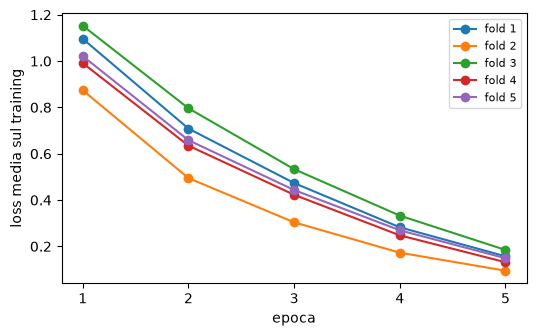

In [4]:
if fatte:
    plt.figure(figsize=(6, 3.5))
    for fold, g in epoche.groupby("fold"):
        plt.plot(g.epoca, g.loss, marker="o", label=f"fold {fold}")
    plt.xticks(range(1, EPOCHE + 1))
    plt.xlabel("epoca")
    plt.ylabel("loss media sul training")
    plt.legend(fontsize=8)
    plt.show()

## 3. BERT contro il classificatore a feature, sui fold già finiti

Per un confronto alla pari, il classificatore a feature viene valutato **solo sugli stessi fold** che BERT ha già completato.

In [5]:
pronti = sorted((LOCALE / "bert").glob(f"{VERSIONE}_{SCHEMA}_fold*.csv"))
bert = pd.concat([pd.read_csv(f) for f in pronti]) if pronti else None
tfidf_tutto = pd.read_csv(LOCALE / f"01_tfidf_{VERSIONE}_{SCHEMA}_articoli.csv")
print("fold di BERT pronti:", sorted(bert.fold.unique()) if bert is not None else "nessuno")

fold di BERT pronti: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [6]:
if bert is not None:
    tfidf = tfidf_tutto[tfidf_tutto.fold.isin(bert.fold.unique())]
    righe = []
    for modello, art in [("TF-IDF + LR", tfidf), ("BERT", bert)]:
        righe.append({"modello": modello, "livello": "articoli", **tabella_per_fold(art).loc["media"]})
        righe.append({"modello": modello, "livello": "testate", **tabella_per_fold(per_testata(art)).loc["media"]})
    display(pd.DataFrame(righe).set_index(["livello", "modello"]).sort_index())

Accuracy  F1 macro  Tolerant α=0.5  Tolerant α=1.0
livello  modello                                                        
articoli BERT            0.360     0.287           0.528           0.695
         TF-IDF + LR     0.389     0.306           0.540           0.692
testate  BERT            0.398     0.327           0.561           0.725
         TF-IDF + LR     0.400     0.327           0.533           0.666

Accuratezza per testata, livello per livello, separando testate **nei gruppi** e **indipendenti** (tra parentesi il numero di testate).

In [7]:
if bert is not None:
    dimensione = tfidf_tutto.groupby("domain").gruppo.first().pipe(lambda g: g.map(g.value_counts()))
    righe = []
    for modello, art in [("TF-IDF + LR", tfidf), ("BERT", bert)]:
        pub = per_testata(art)
        pub["tipo"] = pub.domain.map(dimensione).ge(2).map({True: "nei gruppi", False: "indipendenti"})
        pub["giusta"] = pub.y_true == pub.y_pred
        for (liv, tipo), g in pub.groupby(["y_true", "tipo"]):
            righe.append({"livello": LIVELLI[liv], "testate": tipo, "modello": modello, "valore": f"{g.giusta.mean():.2f} ({len(g)})"})
        for tipo, g in pub.groupby("tipo"):
            righe.append({"livello": "tutti", "testate": tipo, "modello": modello, "valore": f"{g.giusta.mean():.2f} ({len(g)})"})
    display(pd.DataFrame(righe).pivot(index=["livello", "testate"], columns="modello", values="valore")[["TF-IDF + LR", "BERT"]])

modello              TF-IDF + LR        BERT
livello testate                             
l1      indipendenti   0.11 (18)   0.22 (18)
        nei gruppi    0.01 (134)  0.04 (134)
l2      indipendenti   0.64 (42)   0.62 (42)
        nei gruppi     0.54 (24)   0.21 (24)
l3      indipendenti   0.26 (39)   0.23 (39)
        nei gruppi     0.88 (56)   0.88 (56)
l4      indipendenti   0.57 (72)   0.54 (72)
        nei gruppi     0.25 (16)   0.50 (16)
l5      indipendenti   0.12 (32)   0.22 (32)
        nei gruppi      0.00 (3)    0.00 (3)
tutti   indipendenti  0.41 (203)  0.42 (203)
        nei gruppi    0.29 (233)  0.29 (233)